Operaciones de aprendizaje automático
Semana 3/4 | Actividad | Dataset - Notebook | Individual

Daniela Hernández López
A01840424

In [88]:
#Se importan todas las librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import mlflow
import mlflow.sklearn

%pip install seaborn
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, PowerTransformer, OrdinalEncoder, OneHotEncoder, StandardScaler

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.metrics import make_scorer

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, classification_report, f1_score, precision_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay





Note: you may need to restart the kernel to use updated packages.


In [89]:
#Se configura la URI para MLflow
#Primero iniciar la interfaz de usuario de MLflow en la terminal con el comando: mlflow ui
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Notebook-Baseline-Sem4")

<Experiment: artifact_location='mlflow-artifacts:/2', creation_time=1791766806786, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1791766806786, lifecycle_stage='active', name='Notebook-Baseline-Sem4', tags={}, trace_location=None, workspace='default'>

In [90]:
# Se utilizará el dataset de South German Credit para este proyecto. 
# Se puede descargar desde el siguiente enlace: https://archive.ics.uci.edu/dataset/522/south+german+credit
df = pd.read_csv(
    r"c:\Users\ingda\Documents\5_Tec Maestría IA\7_MLOps\Semana 4\Actividad_Semana4\southgermancredit_project\data\raw\SouthGermanCredit.asc",
    sep=r"\s+",
    engine="python"
)

print("Forma del dataset")
print(df.shape)

Forma del dataset
(1000, 21)


In [91]:
# Renombramos los nombres de las columnas del alemán al inglés y desplegamos de
# nuevo el DataFrame para ver el resultado obtenido:

column_mapping = {
    "laufkont": "status",
    "laufzeit": "duration",
    "moral": "credit_history",
    "verw": "purpose",
    "hoehe": "amount",
    "sparkont": "savings",
    "beszeit": "employment_duration",
    "rate": "installment_rate",
    "famges": "personal_status_sex",
    "buerge": "other_debtors",
    "wohnzeit": "present_residence",
    "verm": "property",
    "alter": "age",
    "weitkred": "other_installment_plans",
    "wohn": "housing",
    "bishkred": "number_credits",
    "beruf": "job",
    "pers": "people_liable",
    "telef": "telephone",
    "gastarb": "foreign_worker",
    "kredit": "credit_risk"
}

df.rename(columns=column_mapping, inplace=True)
df.head().T

,0,1,2,3,4
status,1,1,2,1,1
duration,18,9,12,12,12
credit_history,4,4,2,4,4
purpose,2,0,9,0,0
amount,1049,2799,841,2122,2171
savings,1,1,2,1,1
employment_duration,2,3,4,3,3
installment_rate,4,2,2,3,4
personal_status_sex,2,3,2,3,3
other_debtors,1,1,1,1,1


In [92]:
# Etiquetas originales:
# 1 : El préstamo fue reembolsado (buen cliente)
# 0 : El préstamo no fue reembolsado (mal cliente)

# Se cambiará la etiqueta a la variable objetivo para que sea más intuitiva, de la siguiente manera:
# 1 : El préstamo no fue reembolsado (mal cliente)
# 0 : El préstamo fue reembolsado (buen cliente)

df["credit_risk"] = np.where(df["credit_risk"] == 1, 0, 1)

print(df["credit_risk"].value_counts())

credit_risk
0    700
1    300
Name: count, dtype: int64


In [93]:
print("\n -- INFO --")
print(df.info())


 -- INFO --
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   status                   1000 non-null   int64
 1   duration                 1000 non-null   int64
 2   credit_history           1000 non-null   int64
 3   purpose                  1000 non-null   int64
 4   amount                   1000 non-null   int64
 5   savings                  1000 non-null   int64
 6   employment_duration      1000 non-null   int64
 7   installment_rate         1000 non-null   int64
 8   personal_status_sex      1000 non-null   int64
 9   other_debtors            1000 non-null   int64
 10  present_residence        1000 non-null   int64
 11  property                 1000 non-null   int64
 12  age                      1000 non-null   int64
 13  other_installment_plans  1000 non-null   int64
 14  housing                  1000 non-null   int64
 15  num

In [94]:
# Valores faltantes
print("\nValores faltantes")
print(df.isnull().sum())


Valores faltantes
status                     0
duration                   0
credit_history             0
purpose                    0
amount                     0
savings                    0
employment_duration        0
installment_rate           0
personal_status_sex        0
other_debtors              0
present_residence          0
property                   0
age                        0
other_installment_plans    0
housing                    0
number_credits             0
job                        0
people_liable              0
telephone                  0
foreign_worker             0
credit_risk                0
dtype: int64


In [95]:
#Valores duplicados
print("Duplicados:", df.duplicated().sum())

Duplicados: 0


Aunque se indica realizar la división entrenamiento/prueba en el Paso 4, se realiza previamente una partición estratificada de los datos para evitar data leakage. El conjunto de prueba se mantiene aislado de las decisiones de limpieza, transformación y selección del modelo. El EDA descriptivo inicial se realizó sobre el dataset completo, mientras que cualquier análisis utilizado para definir transformaciones o parámetros del modelo se realiza exclusivamente sobre el conjunto de entrenamiento.

In [96]:
# Particionamos los datos de entrada (X) y de salida (y):
X,y = df.iloc[:,:-1], df.iloc[:,-1]

Xtrain, Xtest, ytrain, ytest = train_test_split(X, 
                                                y, 
                                                train_size=0.7, 
                                                stratify=y, 
                                                shuffle=True,
                                                random_state=42)

# Mostramos las dimensiones de la partición generada:
print('X, y Train:')
print(Xtrain.shape)
print('\nX, y Test:')
print(Xtest.shape)

# El umbral de referencia sería el valor de la clase mayoritaria, en este caso 70%.
# La clase mayoritaria constituye un baseline ingenuo.
# Si la clase mayoritaria representa aproximadamente el 70% de los casos, un clasificador que siempre predijera dicha clase tendría un accuracy
# de aproximadamente 70%. Este valor sirve como referencia para comparar el desempeño del modelo.

X, y Train:
(700, 20)

X, y Test:
(300, 20)


In [97]:
# Separamos las variables para poder usar diferentes pipelines de preprocesamiento para cada tipo de variable. 

# Variables numéricas:
list_paper_num = 'duration', 'amount', 'age', 'people_liable'

# Variables ordinales:
list_paper_ord = 'employment_duration', 'installment_rate', 'present_residence', 'property', 'number_credits', 'job'

# Variables nominales/categóricas:
list_paper_cat = 'status', 'credit_history', 'purpose', 'savings', 'personal_status_sex', 'other_debtors', 'other_installment_plans', 'housing', 'telephone', 'foreign_worker'
#no se incluye credit_risk por ser la variable de salida y


Numéricas:


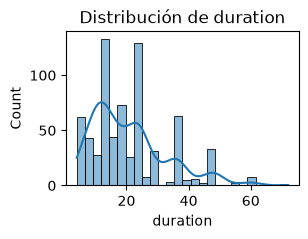


duration
count    700.000000
mean      20.761429
std       12.055734
min        4.000000
25%       12.000000
50%       18.000000
75%       24.000000
max       72.000000
Name: duration, dtype: float64


          count  percentage
duration                   
24          129       18.43
12          126       18.00
18           73       10.43
36           63        9.00
6            58        8.29
15           43        6.14
9            33        4.71
48           32        4.57
30           28        4.00
21           22        3.14
10           20        2.86
60            8        1.14
11            8        1.14
27            7        1.00
42            6        0.86
8             6        0.86
39            5        0.71
7             4        0.57
4             4        0.57
14            4        0.57
20            3        0.43
33            3        0.43
28            3        0.43
13            3        0.43
45            2        0.29
54            2        0.29
72           

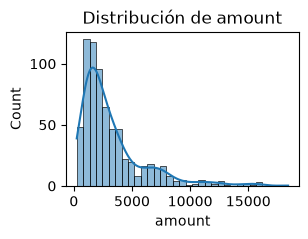


amount
count      700.000000
mean      3212.212857
std       2799.137772
min        250.000000
25%       1373.500000
50%       2278.500000
75%       3877.250000
max      18424.000000
Name: amount, dtype: float64


        count  percentage
amount                   
1275        3        0.43
1258        3        0.43
1393        3        0.43
6468        2        0.29
1924        2        0.29
...       ...         ...
1358        1        0.14
902         1        0.14
1516        1        0.14
250         1        0.14
1402        1        0.14

[662 rows x 2 columns]
------------------------------------------------------------------------------------------------------------------------------------------------------


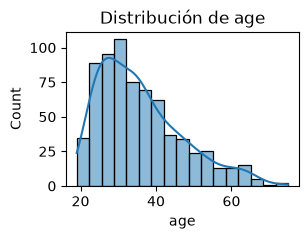


age
count    700.000000
mean      35.792857
std       11.104972
min       19.000000
25%       27.000000
50%       34.000000
75%       42.000000
max       75.000000
Name: age, dtype: float64


     count  percentage
age                   
27      35        5.00
26      33        4.71
23      33        4.71
36      32        4.57
24      30        4.29
30      29        4.14
34      29        4.14
28      27        3.86
35      27        3.86
25      26        3.71
31      26        3.71
32      26        3.71
29      25        3.57
40      23        3.29
38      19        2.71
33      19        2.71
37      18        2.57
22      16        2.29
42      15        2.14
43      14        2.00
47      13        1.86
45      13        1.86
41      12        1.71
46      12        1.71
39      12        1.71
44      10        1.43
21       9        1.29
48       9        1.29
51       8        1.14
52       8        1.14
49       8        1.14
50       8        1.14
20       8        1.14
53

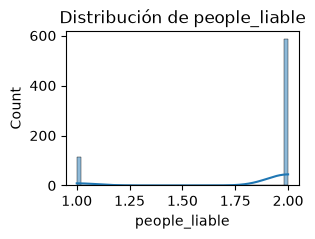


people_liable
count    700.000000
mean       1.838571
std        0.368189
min        1.000000
25%        2.000000
50%        2.000000
75%        2.000000
max        2.000000
Name: people_liable, dtype: float64


               count  percentage
people_liable                   
2                587       83.86
1                113       16.14
------------------------------------------------------------------------------------------------------------------------------------------------------


In [98]:
#-- EDA --
# Numéricas
print('\nNuméricas:')

for col in list_paper_num:
    plt.figure(figsize=(3, 2))
    sns.histplot(Xtrain[col], kde=True)
    plt.title(f"Distribución de {col}")
    plt.show()

    print(f"\n{col}")
    print(Xtrain[col].describe().T)
    print('\n')

    counts = Xtrain[col].value_counts()
    perc = Xtrain[col].value_counts(normalize=True) * 100
    summary = pd.DataFrame({"count": counts, "percentage": perc.round(2)})
    print(summary)
    print("-"*150)


 Variables Ordinales


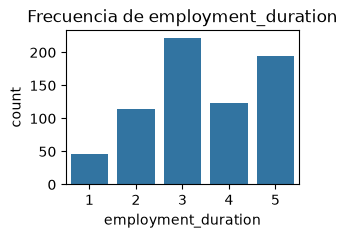

                     count  percentage
employment_duration                   
3                      222       31.71
5                      194       27.71
4                      123       17.57
2                      115       16.43
1                       46        6.57
------------------------------------------------------------------------------------------------------------------------------------------------------


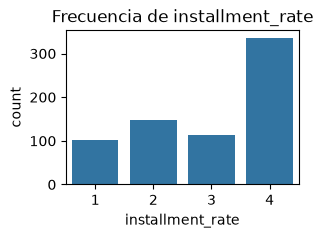

                  count  percentage
installment_rate                   
4                   336       48.00
2                   148       21.14
3                   114       16.29
1                   102       14.57
------------------------------------------------------------------------------------------------------------------------------------------------------


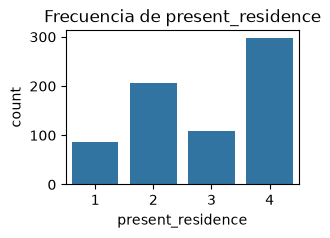

                   count  percentage
present_residence                   
4                    298       42.57
2                    207       29.57
3                    108       15.43
1                     87       12.43
------------------------------------------------------------------------------------------------------------------------------------------------------


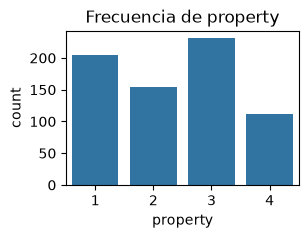

          count  percentage
property                   
3           231       33.00
1           204       29.14
2           154       22.00
4           111       15.86
------------------------------------------------------------------------------------------------------------------------------------------------------


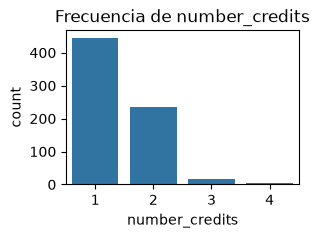

                count  percentage
number_credits                   
1                 445       63.57
2                 235       33.57
3                  16        2.29
4                   4        0.57
------------------------------------------------------------------------------------------------------------------------------------------------------


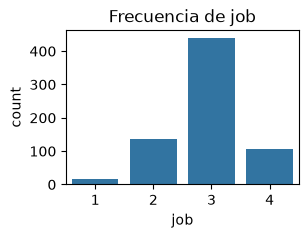

     count  percentage
job                   
3      440       62.86
2      137       19.57
4      107       15.29
1       16        2.29
------------------------------------------------------------------------------------------------------------------------------------------------------


In [99]:
# Ordinales
print("\n Variables Ordinales")
for col in list_paper_ord:
    plt.figure(figsize=(3, 2))
    plt.title(f"Frecuencia de {col}")
    sns.countplot(x=Xtrain[col])
    plt.show()

    counts = Xtrain[col].value_counts()
    perc = Xtrain[col].value_counts(normalize=True) * 100
    summary = pd.DataFrame({"count": counts, "percentage": perc.round(2)})
    print(summary)
    print("-"*150)



Categóricas:


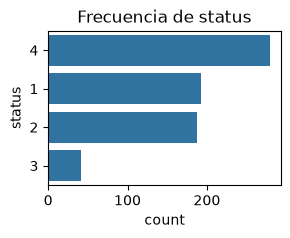

        count  percentage
status                   
4         279       39.86
1         193       27.57
2         187       26.71
3          41        5.86
------------------------------------------------------------------------------------------------------------------------------------------------------


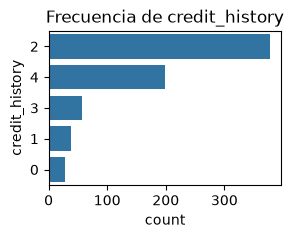

                count  percentage
credit_history                   
2                 378       54.00
4                 199       28.43
3                  57        8.14
1                  38        5.43
0                  28        4.00
------------------------------------------------------------------------------------------------------------------------------------------------------


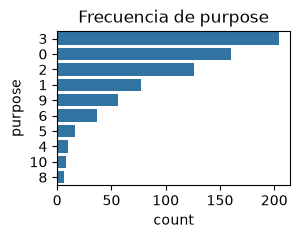

         count  percentage
purpose                   
3          204       29.14
0          160       22.86
2          126       18.00
1           77       11.00
9           56        8.00
6           37        5.29
5           16        2.29
4           10        1.43
10           8        1.14
8            6        0.86
------------------------------------------------------------------------------------------------------------------------------------------------------


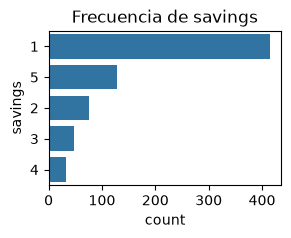

         count  percentage
savings                   
1          415       59.29
5          129       18.43
2           76       10.86
3           47        6.71
4           33        4.71
------------------------------------------------------------------------------------------------------------------------------------------------------


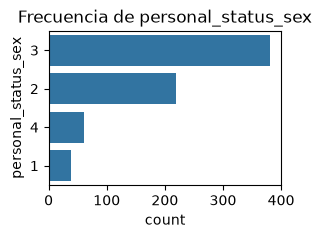

                     count  percentage
personal_status_sex                   
3                      381       54.43
2                      220       31.43
4                       61        8.71
1                       38        5.43
------------------------------------------------------------------------------------------------------------------------------------------------------


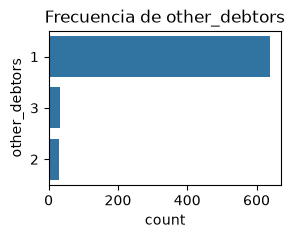

               count  percentage
other_debtors                   
1                639       91.29
3                 32        4.57
2                 29        4.14
------------------------------------------------------------------------------------------------------------------------------------------------------


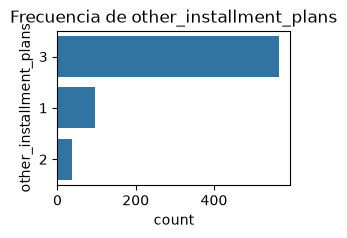

                         count  percentage
other_installment_plans                   
3                          566       80.86
1                           96       13.71
2                           38        5.43
------------------------------------------------------------------------------------------------------------------------------------------------------


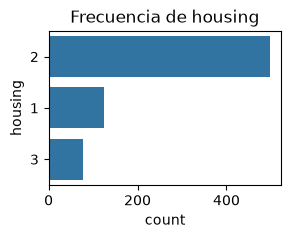

         count  percentage
housing                   
2          498       71.14
1          125       17.86
3           77       11.00
------------------------------------------------------------------------------------------------------------------------------------------------------


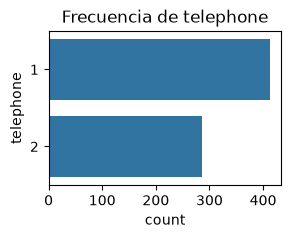

           count  percentage
telephone                   
1            413        59.0
2            287        41.0
------------------------------------------------------------------------------------------------------------------------------------------------------


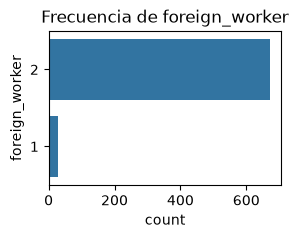

                count  percentage
foreign_worker                   
2                 672        96.0
1                  28         4.0
------------------------------------------------------------------------------------------------------------------------------------------------------


In [100]:
# Nominales / Categóricas
print('\nCategóricas:')

for col in list_paper_cat:
    plt.figure(figsize=(3, 2))
    sns.countplot(y=Xtrain[col], order=Xtrain[col].value_counts().index)
    plt.title(f"Frecuencia de {col}")
    plt.show()

    counts = Xtrain[col].value_counts()
    perc = Xtrain[col].value_counts(normalize=True) * 100
    summary = pd.DataFrame({"count": counts, "percentage": perc.round(2)})
    print(summary)
    print("-"*150)

In [101]:
# Unimos las variables predictoras de TRAIN con la variable objetivo
train_eda = Xtrain.copy()
train_eda["credit_risk"] = ytrain

# 0 = buen crédito / 1 = mal crédito
train_eda.head()

,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
97,2,36,3,9,4455,1,3,2,1,1,...,1,30,2,2,2,4,2,2,2,1
64,1,12,3,0,1344,1,3,4,3,1,...,1,43,3,2,2,2,1,1,2,0
947,4,30,1,1,7485,5,1,4,2,1,...,1,53,1,2,1,4,2,2,2,1
308,1,21,2,3,2606,1,2,4,2,1,...,2,28,3,1,1,4,2,2,2,0
37,4,12,4,3,1934,1,5,2,3,1,...,4,26,3,2,2,3,2,1,2,0


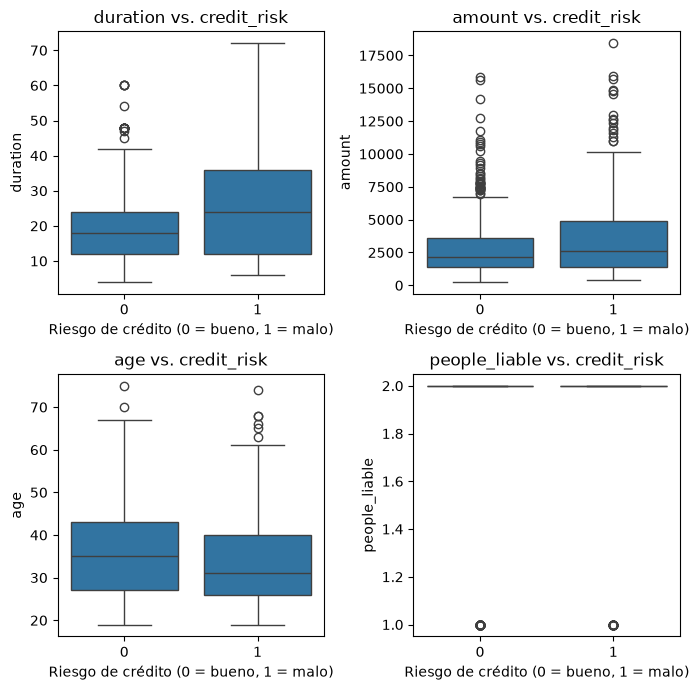

In [102]:
# Boxplots de variables numéricas respecto a la variable objetivo

fig, axes = plt.subplots(2, 2, figsize=(7, 7))

for ax, col in zip(axes.flatten(), list_paper_num):
    sns.boxplot(
        data=train_eda,
        x="credit_risk",
        y=col,
        ax=ax
    )
    
    ax.set_title(f"{col} vs. credit_risk")
    ax.set_xlabel("Riesgo de crédito (0 = bueno, 1 = malo)")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

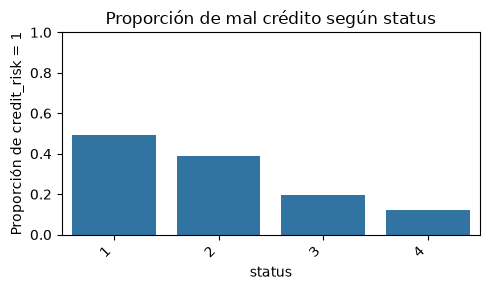

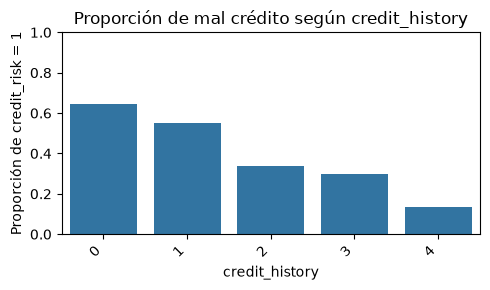

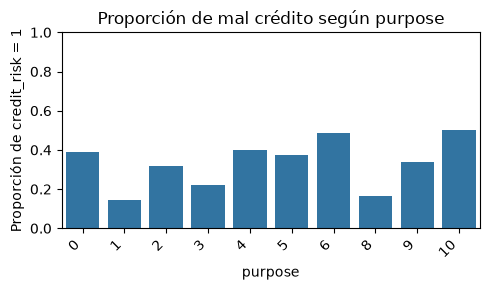

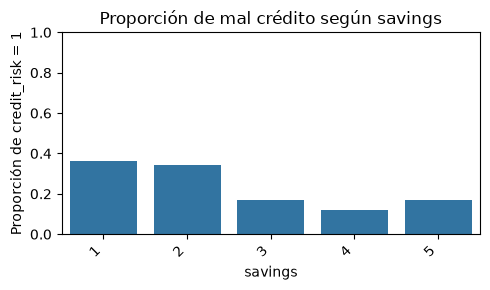

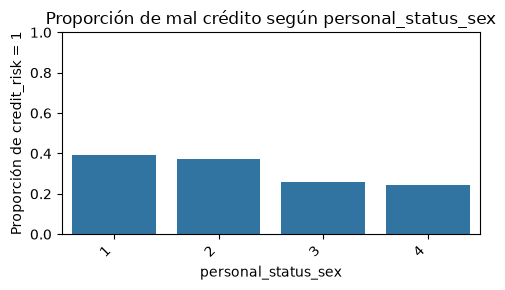

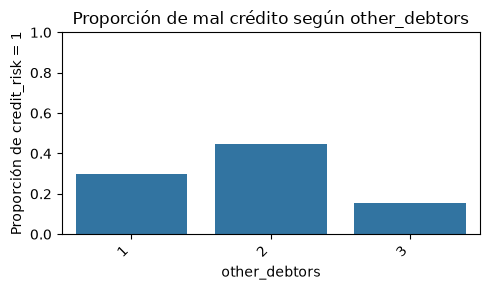

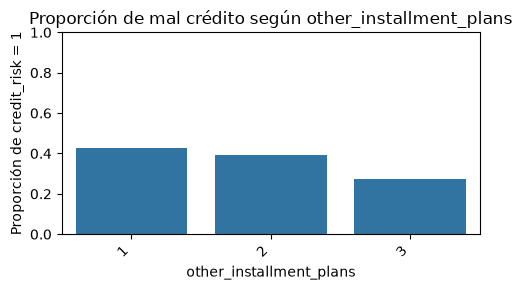

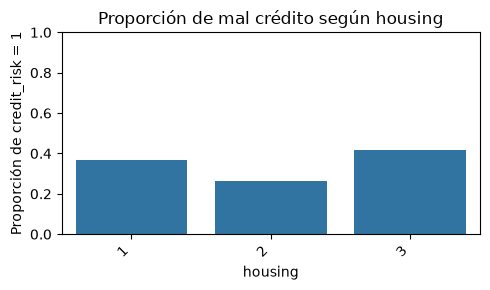

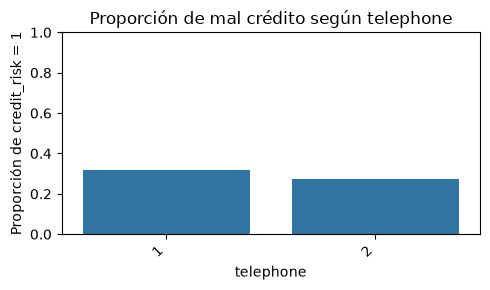

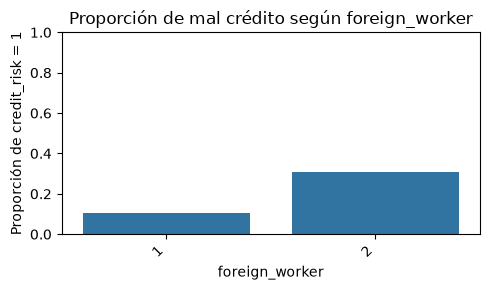

In [103]:
# Proporción de créditos de riesgo (credit_risk = 1)
# dentro de cada categoría

for col in list_paper_cat:
    
    riesgo_por_categoria = (
        train_eda.groupby(col)["credit_risk"]
        .mean()
        .sort_values(ascending=False)
    )
    
    plt.figure(figsize=(5, 3))
    
    sns.barplot(
        x=riesgo_por_categoria.index,
        y=riesgo_por_categoria.values
    )
    
    plt.title(f"Proporción de mal crédito según {col}")
    plt.xlabel(col)
    plt.ylabel("Proporción de credit_risk = 1")
    plt.xticks(rotation=45, ha="right")
    plt.ylim(0, 1)
    
    plt.tight_layout()
    plt.show()

In [104]:
# Promedio de variables numéricas según la clase de riesgo

list_num = ["duration", "amount", "age", "people_liable"]

train_eda.groupby("credit_risk")[list_num].agg(
    ["mean", "median", "std"]
)

duration                         amount                       \
                  mean median        std         mean  median          std   
credit_risk                                                                  
0            19.169388   18.0  11.044893  2905.685714  2176.0  2348.515723   
1            24.476190   24.0  13.448534  3927.442857  2628.0  3544.810187   

                   age                   people_liable                   
                  mean median        std          mean median       std  
credit_risk                                                              
0            36.308163   35.0  10.917844      1.840816    2.0  0.366221  
1            34.590476   31.0  11.466360      1.833333    2.0  0.373569

In [105]:
# Proporción de mal crédito por categoría

for col in list_paper_cat:
    print(f"\n--- {col} ---")
    
    resumen = (
        train_eda.groupby(col)["credit_risk"]
        .agg(["mean", "count"])
        .sort_values("mean", ascending=False)
    )
    
    resumen["percentage_risk"] = resumen["mean"] * 100
    
    print(resumen)


--- status ---
            mean  count  percentage_risk
status                                  
1       0.492228    193        49.222798
2       0.390374    187        39.037433
3       0.195122     41        19.512195
4       0.121864    279        12.186380

--- credit_history ---
                    mean  count  percentage_risk
credit_history                                  
0               0.642857     28        64.285714
1               0.552632     38        55.263158
2               0.335979    378        33.597884
3               0.298246     57        29.824561
4               0.135678    199        13.567839

--- purpose ---
             mean  count  percentage_risk
purpose                                  
10       0.500000      8        50.000000
6        0.486486     37        48.648649
4        0.400000     10        40.000000
0        0.387500    160        38.750000
5        0.375000     16        37.500000
9        0.339286     56        33.928571
2        0.317460 

In [106]:
# Transformaciones y limpieza

# Variables numéricas:
num_pipe = Pipeline([
                    ("imputer", SimpleImputer(strategy="median")), #para rellenar los valores faltantes con la mediana de cada variable
                                                                   # se usa la mediana en lugar de la media para evitar que los valores atípicos influyan en el valor de imputación
                    ("yeojohnson", PowerTransformer(method="yeo-johnson")), #modifica la distribución original para aproximarla a una distribución más simétrica
                                                                            #aquí los outliers no son un problema, ya que el PowerTransformer es robusto frente a ellos
                    ("scaler", StandardScaler()) # coloca los valores de cada variable en una distribución con media 0 y desviación estándar 1
                    ])
num_pipe_nombres = ['duration', 'amount', 'age', 'people_liable']


#-------------------------------------------------------------------------------------------------------------
# Variables categóricas/nominales/binarias:

# Función para agrupar categorías raras (<5%)
def find_rare_categories(df, variables, threshold=0.05):
    """
    Identifica las categorías raras usando únicamente el conjunto de entrenamiento.
    """
    rare_categories = {}
    for col in variables:
        freqs = df[col].value_counts(normalize=True)
        rare_categories[col] = freqs[freqs < threshold].index.tolist()
    return rare_categories

def group_rare_categories(df, rare_categories):
    """
    Agrupa como 'other' las categorías que fueron identificadas como raras en el conjunto de entrenamiento.
    """
    df_copy = df.copy()
    for col, categories in rare_categories.items():
        df_copy[col] = df_copy[col].replace(categories, "other")
    return df_copy

# Variables categóricas donde aplicamos agrupación
rare_vars = ["credit_history", "purpose", "other_debtors"]

# Identificamos las categorías raras SOLO utilizando el conjunto de entrenamiento
rare_categories = find_rare_categories(
    Xtrain,
    rare_vars,
    threshold=0.05
)
# Aplicamos las mismas categorías raras identificadas en train
# tanto a train como a test
Xtrain_grouped = group_rare_categories(
    Xtrain,
    rare_categories
)
Xtest_grouped = group_rare_categories(
    Xtest,
    rare_categories
)

# Asegurar que todas las columnas categóricas y ordinales sean de tipo string
# para evitar el TypeError en los codificadores debido a tipos int/str mixtos.
for col in list_paper_cat + list_paper_ord:
    Xtrain_grouped[col] = Xtrain_grouped[col].astype(str)
    Xtest_grouped[col] = Xtest_grouped[col].astype(str)


nom_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")), #para rellenar los valores faltantes con la moda de cada variable
    ("onehot", OneHotEncoder(handle_unknown="ignore"))      #convierte las variables categóricas en variables binarias (0/1) para cada categoría
                                                            #se usa One-Hot Encoder en lugar de Ordinal Encoder para evitar que el modelo interprete un orden en las categorías
])
nom_pipe_nombres = ['status', 'credit_history', 'purpose', 'savings', 'personal_status_sex', 'other_debtors', 'other_installment_plans', 'housing', 'telephone', 'foreign_worker']


#-------------------------------------------------------------------------------------------------------------
# Variables ordinales:
ord_pipe = Pipeline([
                    ("imputer", SimpleImputer(strategy="most_frequent")), #para rellenar los valores faltantes con la moda de cada variable
                    ("encoder", OrdinalEncoder()) #convierte las variables ordinales en valores numéricos
                    ])
ord_pipe_nombres = ['employment_duration', 'installment_rate', 'present_residence', 'property', 'number_credits', 'job']



# Conjuntemos las transformaciones de todo tipo de variable y
# dejamos sin procesar aquellas que hayas decidido no transformar:

columnasTransformer = ColumnTransformer([
                    ("num", num_pipe, num_pipe_nombres),
                    ("ord", ord_pipe, ord_pipe_nombres),
                    ("cat", nom_pipe, nom_pipe_nombres)
                     ])



Recall como métrica, es la tasa de verdaderos positivos

Recall = VP / (VP + FN)

donde los VP son clientes riesgosos (Credit_risk=1) correctamente identificados y FN clientes riesgosos que el modelo dejó pasar. Para este ejercicio nos interesa identificar a aquellas personas que en credit_risk = 1, es decir que no hay que otorgarles el crédito porque de lo contrario se le estaría otorgando un crédito a una persona que probablemente no pagará, lo que significa una pérdida financiera.

In [107]:
# Baseline - Referencia ingenua: siempre predecir la clase mayoritaria (0 = buen crédito)
# Métrica principal: Recall de la clase 1 (mal crédito)
mi_metrica = make_scorer(recall_score)

# Validación cruzada estratificada
cv = RepeatedStratifiedKFold(
    n_splits=3,
    n_repeats=3,
    random_state=6
)

# Baseline ingenuo:
modeloD = DummyClassifier(
    strategy="most_frequent"
    #strategy="stratified"
)

# Pipeline para mantener el preprocesamiento dentro de cada fold
pipelineD = Pipeline(
    steps=[
        ("ct", columnasTransformer),
        ("Dummy", modeloD)
    ]
)

# Evaluación mediante validación cruzada
scores = cross_val_score(
    pipelineD,
    Xtrain,
    ytrain,
    scoring=mi_metrica,
    cv=cv,
    n_jobs=-1
)

print("Desempeños obtenidos con DummyClassifier y Recall:")
print(scores)

print("\nPromedio y desviación estándar:")
print(
    "Recall = %.3f, std = %.3f"
    % (np.mean(scores), np.std(scores))
)

Desempeños obtenidos con DummyClassifier y Recall:
[0. 0. 0. 0. 0. 0. 0. 0. 0.]

Promedio y desviación estándar:
Recall = 0.000, std = 0.000


In [108]:
#Modelo Baseline Logistic Regression
# Métrica principal: Recall de la clase 1 (mal crédito)
mi_metrica = make_scorer(recall_score)
valorC = 10  # Valor de regularización para Logistic Regression
valor_max_iter = 1000  # Número máximo de iteraciones para la convergencia del modelo
valor_random_state = 6  # Semilla para la reproducibilidad del modelo

# Validación cruzada estratificada
cv = RepeatedStratifiedKFold(
    n_splits=3,
    n_repeats=3,
    random_state=6
)

# Modelo baseline
modeloLR = LogisticRegression(
    C=valorC,
    max_iter=valor_max_iter,
    random_state=valor_random_state
)

# Pipeline: preprocesamiento + modelo
pipelineLR = Pipeline(
    steps=[
        ("ct", columnasTransformer),
        ("LogisticRegression", modeloLR)
    ]
)

# Validación cruzada sobre TRAIN
scoresLR = cross_val_score(
    pipelineLR,
    Xtrain_grouped,
    ytrain,
    scoring=mi_metrica,
    cv=cv,
    n_jobs=-1
)

print("Desempeños obtenidos con Logistic Regression y la métrica Recall:")
print(scoresLR)

print("\nPromedio y desviación estándar:")
print(
    "Recall = %.3f, std = %.3f"
    % (np.mean(scoresLR), np.std(scoresLR))
)

Desempeños obtenidos con Logistic Regression y la métrica Recall:
[0.45714286 0.48571429 0.52857143 0.5        0.42857143 0.51428571
 0.51428571 0.5        0.48571429]

Promedio y desviación estándar:
Recall = 0.490, std = 0.029


El Recall obtenido por Logistic Regression se compara con el Recall del baseline ingenuo. 
Un valor superior al baseline indica que el modelo aporta capacidad adicional para identificar casos de mal crédito.

In [109]:
# ENTRENAMIENTO DEL MODELO BASE + REGISTRO EN MLflow

# 1. Entrenar el modelo con todo el conjunto de entrenamiento
#from zipfile import Path

pipelineLR.fit(Xtrain_grouped, ytrain)

# Resultados obtenidos anteriormente con cross_val_score
recall_mean = np.mean(scoresLR)
recall_std = np.std(scoresLR)
precision = precision_score(
    ytrain,
    pipelineLR.predict(Xtrain_grouped)
)
print(f"Recall promedio CV: {recall_mean:.3f}")
print(f"Desviación estándar CV: {recall_std:.3f}")
print(f"Precisión promedio CV: {precision:.3f}")


# REGISTRO DEL EXPERIMENTO EN MLflow

with mlflow.start_run(run_name="LogisticRegression_Baseline"):

    # Parámetros
    mlflow.log_param("modelo", "Logistic Regression")
    mlflow.log_param("valor_C", valorC)
    mlflow.log_param("max_iter", valor_max_iter)
    mlflow.log_param("random_state", valor_random_state)
    mlflow.log_param("cv_n_splits", 3)
    mlflow.log_param("cv_n_repeats", 3)
    mlflow.log_param("metrica", "Recall")

    # Métricas
    mlflow.log_metric("recall_mean", recall_mean)
    mlflow.log_metric("recall_std", recall_std)
    mlflow.log_metric("precision", precision)


    # Artefacto: gráfica de los resultados de validación cruzada
    plt.figure(figsize=(6, 4))
    plt.bar(
        range(1, len(scoresLR) + 1),
        scoresLR
    )
    plt.xlabel("Fold")
    plt.ylabel("Recall")
    plt.title(f"Recall por fold - Logistic Regression (C={valorC})")
    plt.ylim(0, 1)
    plt.tight_layout()

    plt.savefig("recall_cv.png", dpi=300, bbox_inches="tight")
    plt.close()

    mlflow.log_artifact("recall_cv.png")

    print("Experimento registrado correctamente en MLflow.")

Recall promedio CV: 0.490
Desviación estándar CV: 0.029
Precisión promedio CV: 0.676
Experimento registrado correctamente en MLflow.
🏃 View run LogisticRegression_Baseline at: http://127.0.0.1:5000/#/experiments/2/runs/5a7232ec962943a5806bd97fedd19544
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


Recall en test: 0.4777777777777778


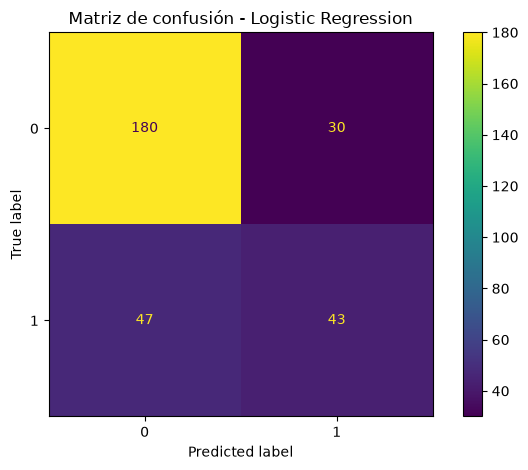

In [110]:
modelo_final = LogisticRegression(
    C=10,
    max_iter=1000,
    random_state=6
)

pipeline_final = Pipeline([
    ("ct", columnasTransformer),
    ("LogisticRegression", modelo_final)
])

pipeline_final.fit(Xtrain_grouped, ytrain)

#Evaluación final con Xtest_grouped
ypred = pipeline_final.predict(Xtest_grouped)
recall_test = recall_score(ytest, ypred)
precision = precision_score(ytest, ypred)
print("Recall en test:", recall_test)

#Matriz de confusión
cm = confusion_matrix(ytest, ypred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Matriz de confusión - Logistic Regression")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()


In [111]:
#Registrar la métrica final en MLflow
with mlflow.start_run(run_name=f"LogisticRegression_C_{valorC}_Final"):

    # Parámetros del modelo
    mlflow.log_param("model", "LogisticRegression")
    mlflow.log_param("C", valorC)
    mlflow.log_param("max_iter", valor_max_iter)
    mlflow.log_param("random_state", valor_random_state)

    # Métrica obtenida durante la validación cruzada
    mlflow.log_metric("recall_cv_mean", np.mean(scoresLR))
    mlflow.log_metric("precision", precision)
   

    # Métrica final sobre el conjunto de prueba
    mlflow.log_metric("recall_test", recall_test)

    # Registrar matriz de confusión como artefacto
    mlflow.log_artifact("confusion_matrix.png")

    # Registrar el modelo entrenado
    mlflow.sklearn.log_model(
        sk_model=pipelineLR,
        name="model",
        skops_trusted_types=["numpy.dtype"]
    )

print("Evaluación final registrada en MLflow.")

🏃 View run LogisticRegression_C_10_Final at: http://127.0.0.1:5000/#/experiments/2/runs/40c7d3fbd04349e191f11f7b5d8ccdd6
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
Evaluación final registrada en MLflow.


Se realizan 4 runs dentro del mismo experimento cambiando 1 de los parámetros
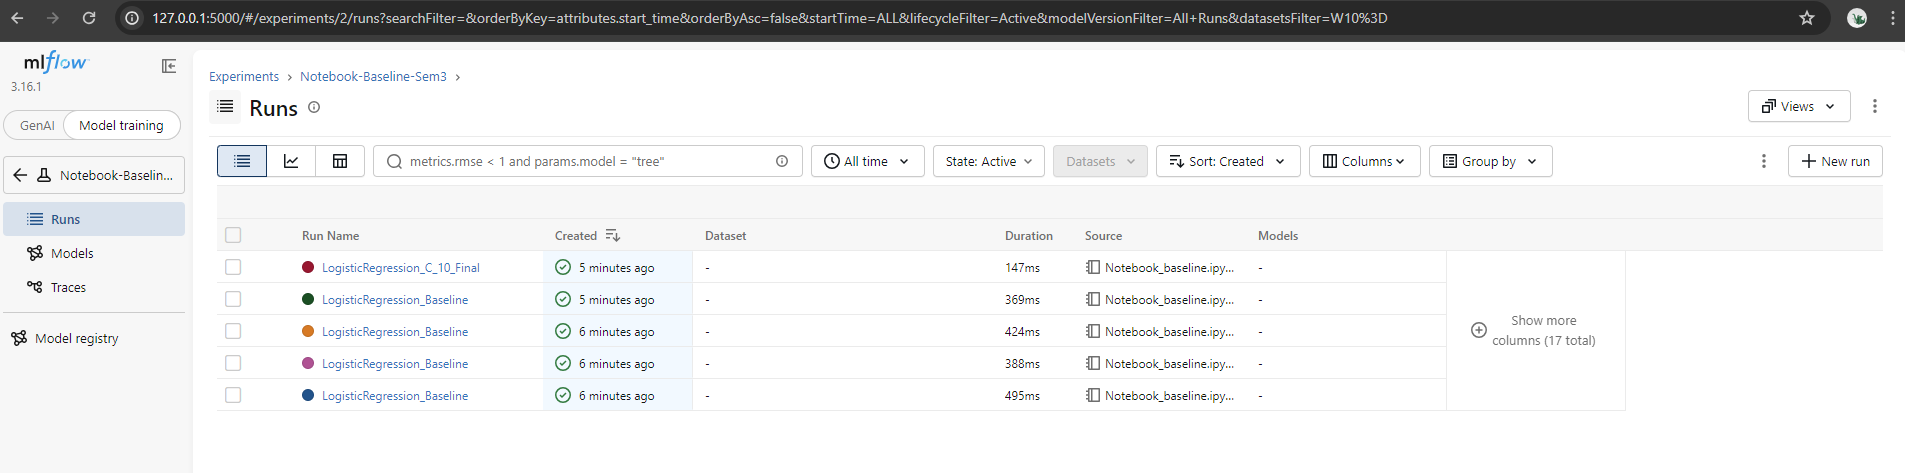

Comparación de los 4 runs
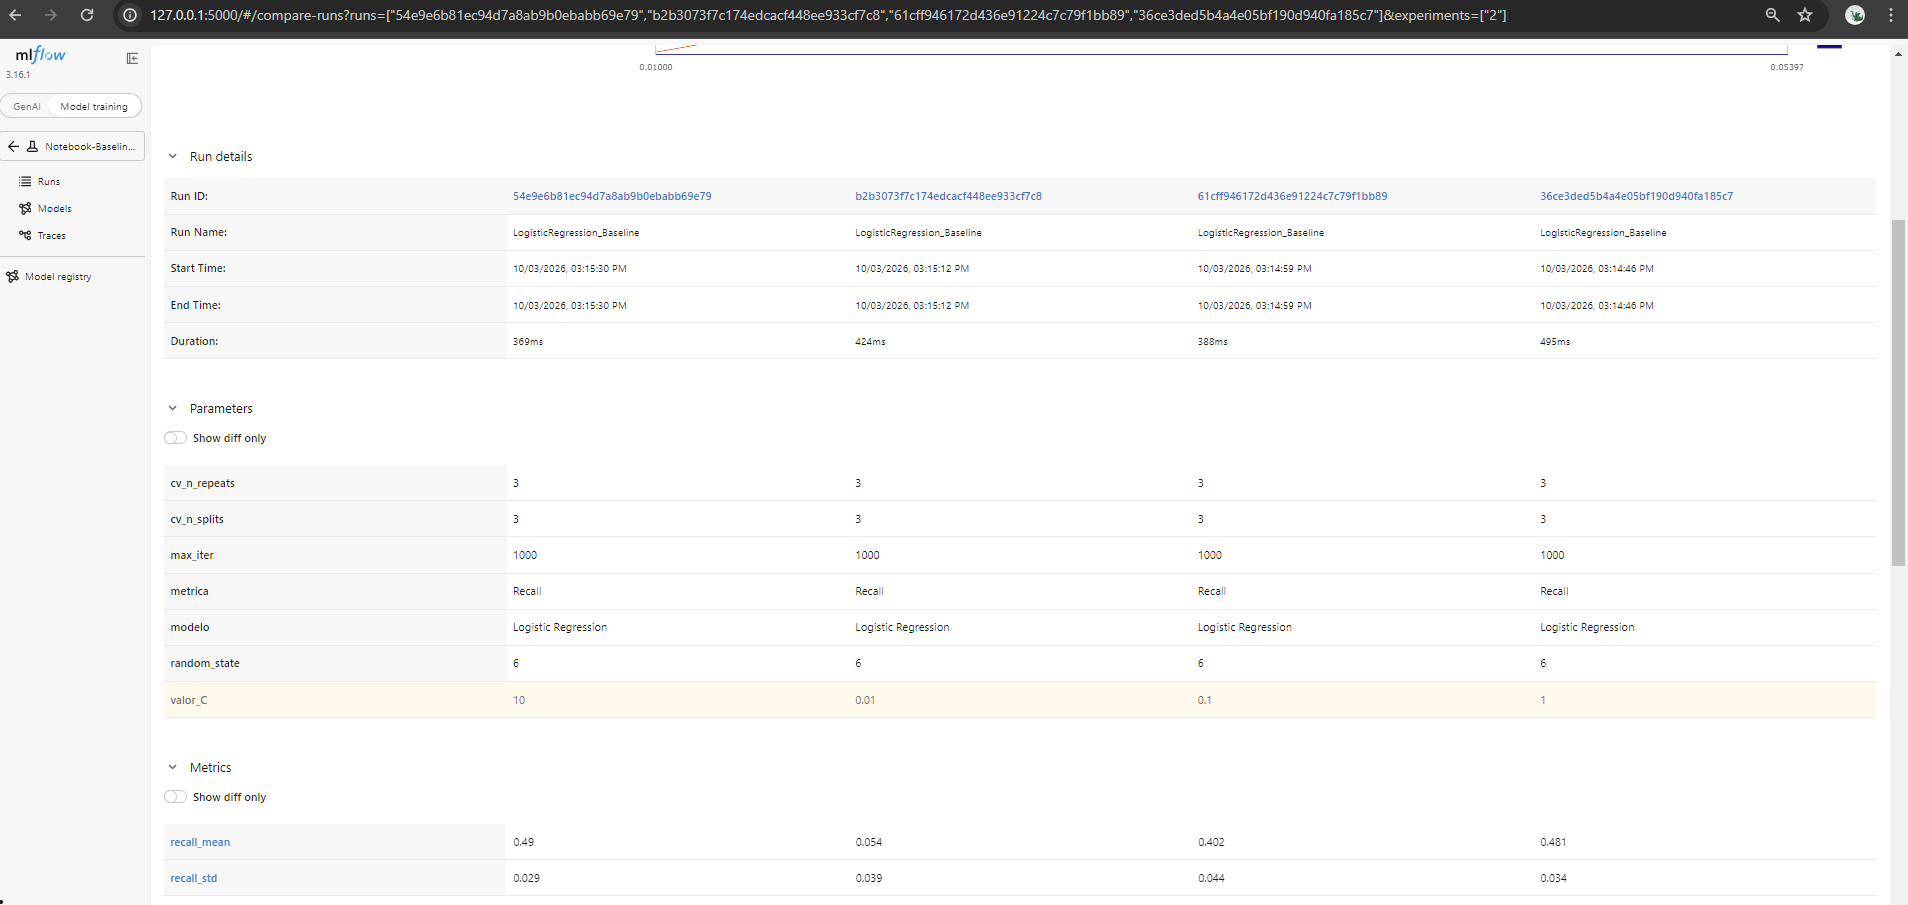

Se incluye un artefacto a cada run que es la gráfica de los resultados de validación cruzada
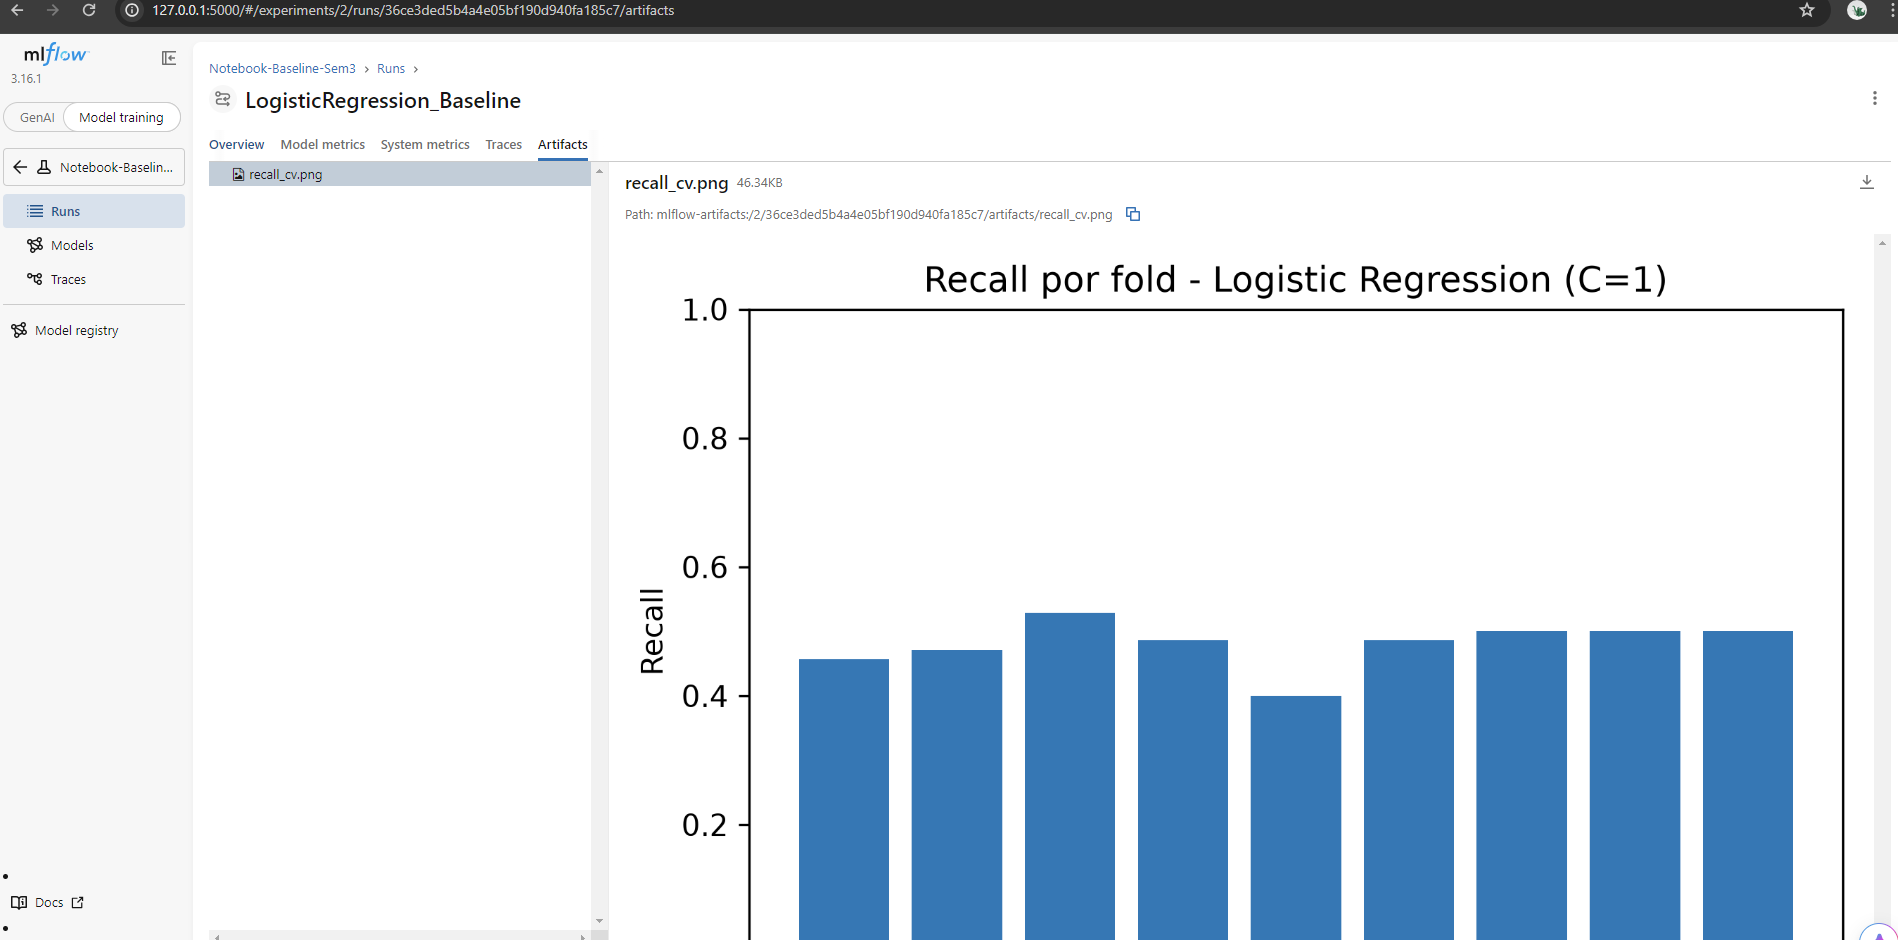

Finalmente se hace un run adicional con los parámetros del mejor modelo
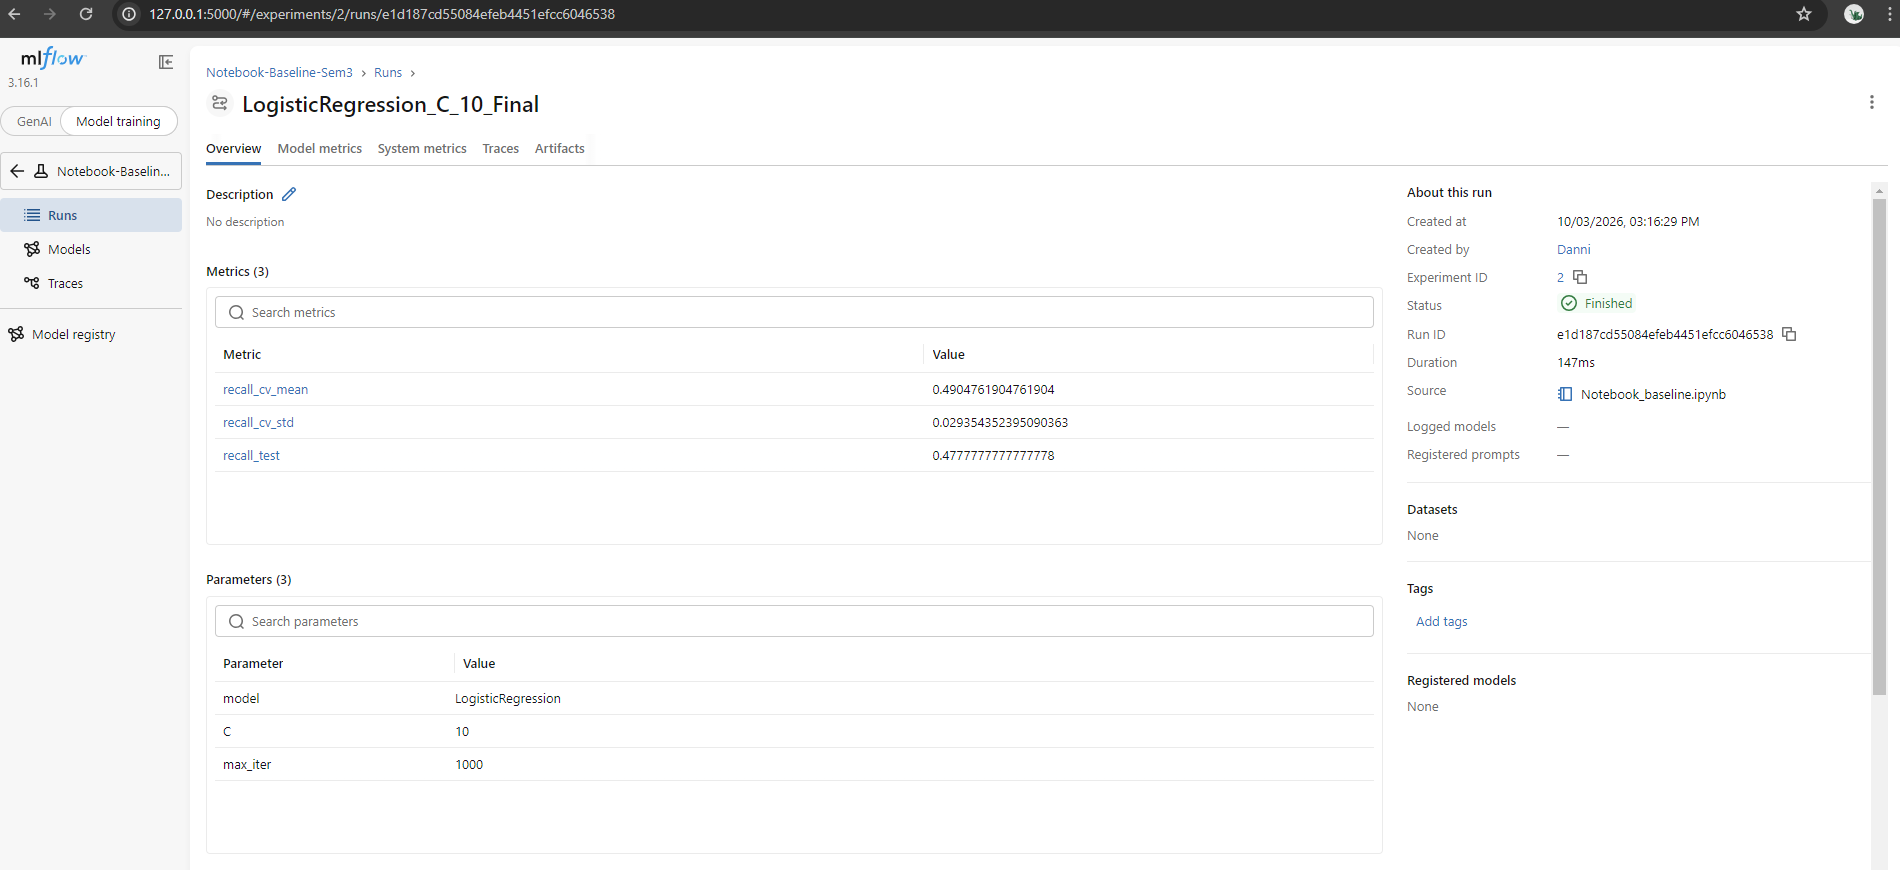

y se incluye la matriz de confusión en los artefactos
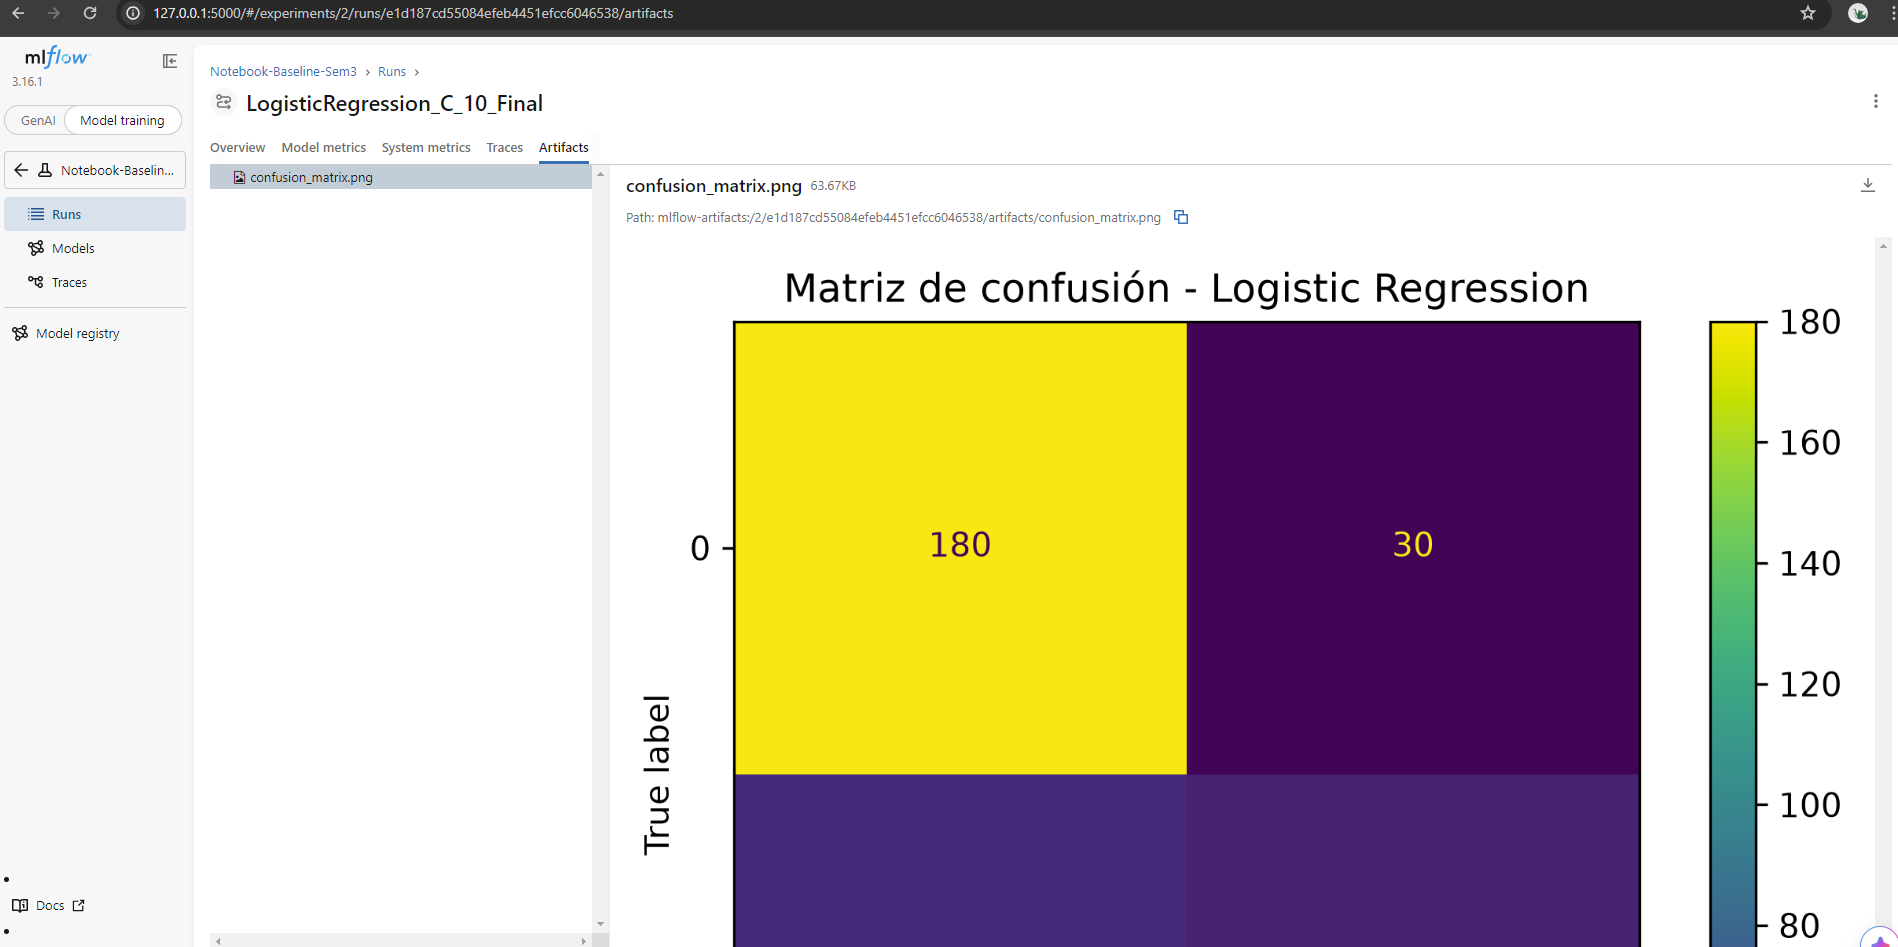

Reflexión:
A partir de este ejercicio, considero que el ciclo de un proyecto de Machine Learning mejora significativamente mediante prácticas de MLOps, principalmente para hacerlo más reproducible, trazable y fácil de mantener.
Es muy importante mantener un registro estructurado de experimentos, hiperparámetros, métricas y artefactos, como se realizó con MLflow durante esta actividad. De esta manera, es posible identificar qué configuración produjo cada resultado y reproducir el experimento posteriormente.

Una de las principales mejoras que incorporaría a este flujo sería automatizar en mayor medida el proceso de entrenamiento y evaluación. Actualmente, parte del flujo se realiza manualmente, por ejemplo, al modificar los parámetros, ejecutar nuevamente el modelo y posteriormente comparar los resultados en MLflow. Mediante prácticas de MLOps sería posible automatizar la ejecución de diferentes configuraciones, registrar sus resultados y seleccionar de manera más sistemática el mejor modelo de acuerdo con la métrica definida. También sería conveniente mantener un control de versiones tanto del código como de los datos y de los modelos generados, de manera que cada resultado pueda relacionarse con una versión específica del proceso.

Aunque actualmente no participo directamente en proyectos de MLOps, estos aprendizajes tienen una relación clara con mi área profesional en ABB. En el diseño de celdas robóticas de paletizado, la confiabilidad, trazabilidad y mantenibilidad de los sistemas son aspectos importantes. Por ejemplo, ante una futura integración de Machine Learning con sistemas de visión o robótica, prácticas como monitoreo y control de configuraciones podrían facilitar la implementación de soluciones consistentes entre diferentes celdas/versiones y reducir riesgos durante cambios o actualizaciones.
Por ello, aunque mi experiencia actual con MLOps es de principiante, este ejercicio me permite identificar cómo sus principios pueden trasladarse a un entorno industrial. Más que enfocarse únicamente en desarrollar un modelo que funcione, MLOps plantea una visión de ciclo de vida completo, donde también importan la operación, el seguimiento, la documentación y la capacidad de mantener la solución a largo plazo.